<a href="https://colab.research.google.com/github/mishraaashkacs242511-maker/Aashka/blob/main/ML_Fundamentals_Prac_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

2. KNN for breast cancer medical diagnosis
Use KNN on Wisconsin Breast Cancer dataset to classify tumors as
benign/malignant (real-world oncology decision support). Compare accuracy with
different distance metrics.

Graph 1: Before implementing KNN

First 5 rows:
   mean radius  mean texture  mean perimeter  mean area  mean smoothness  \
0        17.99         10.38          122.80     1001.0          0.11840   
1        20.57         17.77          132.90     1326.0          0.08474   
2        19.69         21.25          130.00     1203.0          0.10960   
3        11.42         20.38           77.58      386.1          0.14250   
4        20.29         14.34          135.10     1297.0          0.10030   

   mean compactness  mean concavity  mean concave points  mean symmetry  \
0           0.27760          0.3001              0.14710         0.2419   
1           0.07864          0.0869              0.07017         0.1812   
2           0.15990          0.1974              0.12790         0.2069   
3           0.28390          0.2414              0.10520         0.2597   
4           0.13280          0.1980              0.10430         0.1809   

   mean fractal dimension  ...  worst texture  worst perimeter  worst area  \


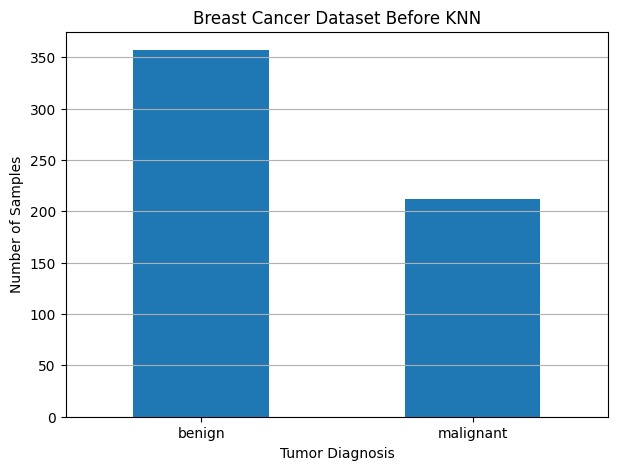

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, classification_report

data = load_breast_cancer()

X = data.data
y = data.target

df = pd.DataFrame(X, columns=data.feature_names)
df['Diagnosis'] = data.target_names[y]

print("First 5 rows:")
print(df.head())

print("\nDataset Shape:", df.shape)

print("\nTumor Distribution:")
print(df['Diagnosis'].value_counts())

df['Diagnosis'].value_counts().plot(
    kind='bar', figsize=(7, 5)
)

plt.title("Breast Cancer Dataset Before KNN")
plt.xlabel("Tumor Diagnosis")
plt.ylabel("Number of Samples")
plt.xticks(rotation=0)
plt.grid(axis='y')
plt.show()

Graph 2: Before and after standardization

Training Samples: 455
Testing Samples: 114

Data Standardization Completed


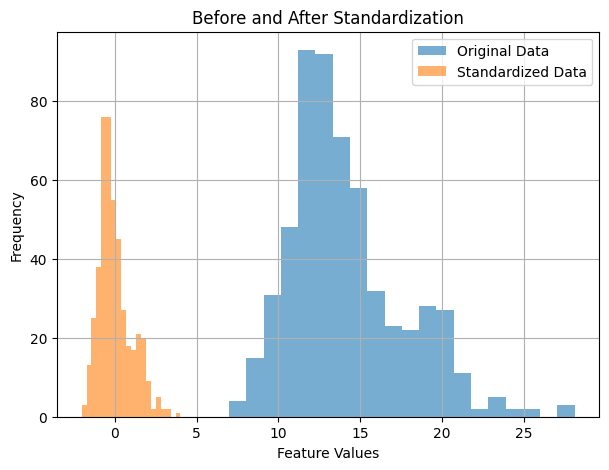

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

print("Training Samples:", len(X_train))
print("Testing Samples:", len(X_test))

print("\nData Standardization Completed")

plt.figure(figsize=(7, 5))

plt.hist(X[:, 0], bins=20, alpha=0.6, label='Original Data')
plt.hist(X_train[:, 0], bins=20, alpha=0.6, label='Standardized Data')

plt.xlabel("Feature Values")
plt.ylabel("Frequency")
plt.title("Before and After Standardization")
plt.legend()
plt.grid()
plt.show()

Graph 3: Actual vs Predicted


Distance Metric: euclidean
Accuracy: 95.61 %

Distance Metric: manhattan
Accuracy: 96.49 %

Distance Metric: minkowski
Accuracy: 95.61 %

Classification Report:
              precision    recall  f1-score   support

   malignant       0.95      0.93      0.94        42
      benign       0.96      0.97      0.97        72

    accuracy                           0.96       114
   macro avg       0.96      0.95      0.95       114
weighted avg       0.96      0.96      0.96       114



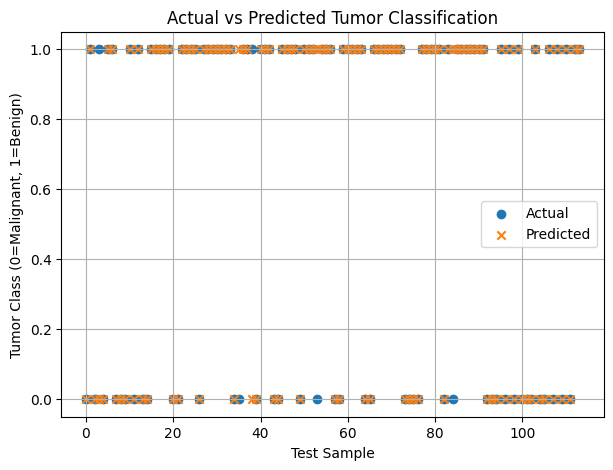

In [ ]:
metrics = ['euclidean', 'manhattan', 'minkowski']

for metric in metrics:

    model = KNeighborsClassifier(
        n_neighbors=5,
        metric=metric
    )

    model.fit(X_train, y_train)

    predictions = model.predict(X_test)

    accuracy = accuracy_score(y_test, predictions)

    print("\nDistance Metric:", metric)
    print("Accuracy:", round(accuracy * 100, 2), "%")

model = KNeighborsClassifier(
    n_neighbors=5,
    metric='euclidean'
)

model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=data.target_names
))

plt.figure(figsize=(7, 5))

plt.scatter(
    range(len(y_test)),
    y_test,
    label='Actual',
    marker='o'
)

plt.scatter(
    range(len(y_pred)),
    y_pred,
    label='Predicted',
    marker='x'
)

plt.xlabel("Test Sample")
plt.ylabel("Tumor Class (0=Malignant, 1=Benign)")
plt.title("Actual vs Predicted Tumor Classification")
plt.legend()
plt.grid()
plt.show()

Graph 4: Accuracy comparison

euclidean Accuracy: 95.61 %
manhattan Accuracy: 96.49 %
minkowski Accuracy: 95.61 %


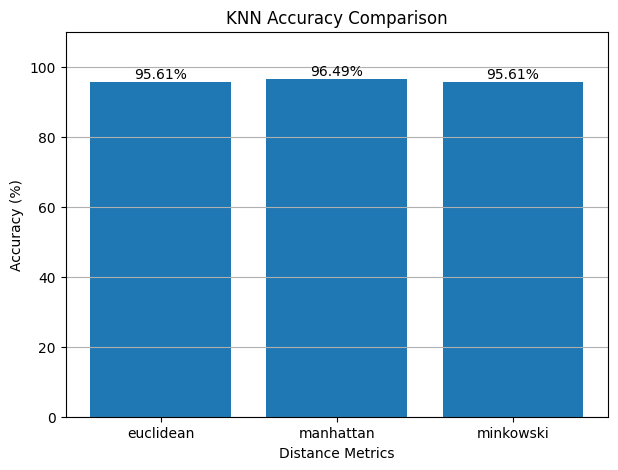

In [ ]:
metrics = ['euclidean', 'manhattan', 'minkowski']
accuracy_values = []

for metric in metrics:

    model = KNeighborsClassifier(
        n_neighbors=5,
        metric=metric
    )

    model.fit(X_train, y_train)

    predictions = model.predict(X_test)

    accuracy = accuracy_score(y_test, predictions)

    accuracy_values.append(accuracy * 100)

    print(metric, "Accuracy:", round(accuracy * 100, 2), "%")

plt.figure(figsize=(7, 5))

plt.bar(metrics, accuracy_values)

plt.xlabel("Distance Metrics")
plt.ylabel("Accuracy (%)")
plt.title("KNN Accuracy Comparison")
plt.ylim(0, 110)
plt.grid(axis='y')

for i, value in enumerate(accuracy_values):
    plt.text(i, value + 1, str(round(value, 2)) + "%",
             ha='center')

plt.show()